##### Cell 1 — Load shared training data

In [1]:

# ==========================================================
# IT3091 - Feature Engineering Investigation
# Responsibility: IT24102178 - Feature Engineering
# Integration: IT24101808
# ==========================================================

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_preparation import (
    load_and_clean_data,
    separate_features_target
)

from src.validation import create_train_test_split

df = load_and_clean_data(project_root)
X, y = separate_features_target(df)

X_train, X_test, y_train, y_test = (
    create_train_test_split(X, y)
)

# EDA work must use training data only from this point
train_df = X_train.copy()
train_df["ChurnBinary"] = y_train

print("Training data:", train_df.shape)
print("Test data:", X_test.shape)


Training data: (5634, 20)
Test data: (1409, 19)


##### Cell 2 — Investigate tenure groups

In [2]:

# Responsibility: IT24102178 - Feature Engineering

tenure_bins = [-1, 12, 24, 48, 72]
tenure_labels = [
    "0-12",
    "13-24",
    "25-48",
    "49-72"
]

train_df["TenureGroup"] = pd.cut(
    train_df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_group_summary = (
    train_df.groupby("TenureGroup", observed=True)["ChurnBinary"]
    .agg(["count", "mean"])
)

tenure_group_summary.columns = [
    "Customers",
    "ChurnRate"
]

tenure_group_summary["ChurnRate"] *= 100

display(tenure_group_summary.round(2))


,Customers,ChurnRate
TenureGroup,,
0-12,1737,47.32
13-24,818,28.61
25-48,1290,20.23
49-72,1789,9.95


##### Cell 3 — Create ServiceCount

In [3]:

# Responsibility: IT24102178 - Feature Engineering

service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

service_indicator = pd.DataFrame(index=train_df.index)

for col in service_columns:
    if col == "InternetService":
        service_indicator[col] = (
            train_df[col] != "No"
        ).astype(int)
    else:
        service_indicator[col] = (
            train_df[col] == "Yes"
        ).astype(int)

train_df["ServiceCount"] = service_indicator.sum(axis=1)

print("ServiceCount distribution:")
print(train_df["ServiceCount"].value_counts().sort_index())

service_count_summary = (
    train_df.groupby("ServiceCount")["ChurnBinary"]
    .agg(["count", "mean"])
)

service_count_summary.columns = [
    "Customers",
    "ChurnRate"
]

service_count_summary["ChurnRate"] *= 100

display(service_count_summary.round(2))


ServiceCount distribution:
ServiceCount
1    998
2    704
3    645
4    777
5    741
6    724
7    552
8    319
9    174
Name: count, dtype: int64


,Customers,ChurnRate
ServiceCount,,
1,998,10.52
2,704,30.97
3,645,43.88
4,777,36.68
5,741,32.52
6,724,26.10
7,552,23.01
8,319,12.23
9,174,4.60


##### Cell 4 — Check numerical feature relationships

,tenure,MonthlyCharges,TotalCharges,ServiceCount
tenure,1.000,0.257,0.830,0.481
MonthlyCharges,0.257,1.000,0.654,0.852
TotalCharges,0.830,0.654,1.000,0.777
ServiceCount,0.481,0.852,0.777,1.000


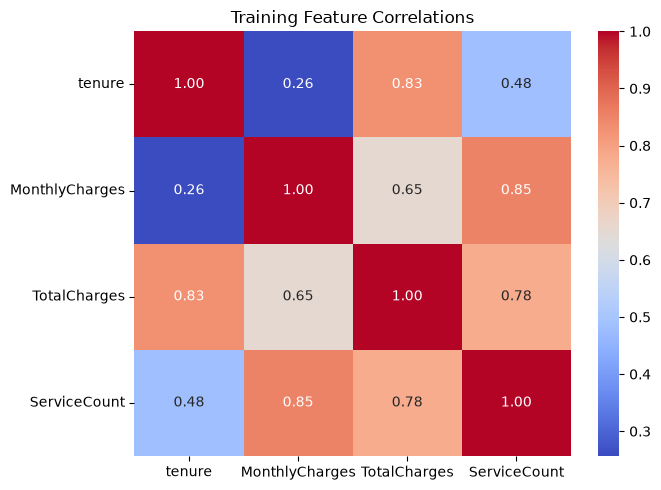

In [4]:

# Responsibility: IT24102178 - Feature Engineering

feature_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ServiceCount"
]

correlation_matrix = train_df[feature_columns].corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Training Feature Correlations")
plt.tight_layout()
plt.show()


##### Verify both feature configurations

In [5]:

# ==========================================================
# Feature engineering verification
# ==========================================================

from src.feature_engineering import TelcoFeatureEngineer

baseline_engineer = TelcoFeatureEngineer(
    add_engineered_features=False
)

engineered_engineer = TelcoFeatureEngineer(
    add_engineered_features=True
)

X_train_baseline = baseline_engineer.fit_transform(X_train)

X_train_engineered = engineered_engineer.fit_transform(X_train)

print("Original features:", X_train.shape[1])
print("Baseline features:", X_train_baseline.shape[1])
print("Engineered features:", X_train_engineered.shape[1])

print("\nNew features:")
print(
    sorted(
        set(X_train_engineered.columns)
        - set(X_train_baseline.columns)
    )
)

display(
    X_train_engineered[
        ["tenure", "TenureGroup", "ServiceCount"]
    ].head(10)
)


Original features: 19
Baseline features: 19
Engineered features: 21

New features:
['ServiceCount', 'TenureGroup']


,tenure,TenureGroup,ServiceCount
3738,35,25-48,4
3151,15,13-24,3
4860,13,13-24,4
3867,26,25-48,6
3810,1,0-12,2
2666,66,49-72,7
2645,1,0-12,1
189,40,25-48,4
5767,65,49-72,4
2257,60,49-72,7


##### Verify the transformation does not modify the original data

In [6]:


print("Original X_train columns:", X_train.shape[1])
print("Engineered columns:", X_train_engineered.shape[1])

print(
    "Original X_train contains ServiceCount:",
    "ServiceCount" in X_train.columns
)

print(
    "Original X_train contains TenureGroup:",
    "TenureGroup" in X_train.columns
)

print(
    "Missing engineered values:",
    X_train_engineered[
        ["TenureGroup", "ServiceCount"]
    ].isna().sum().sum()
)


Original X_train columns: 19
Engineered columns: 21
Original X_train contains ServiceCount: False
Original X_train contains TenureGroup: False
Missing engineered values: 0
